# ESP32 capture manifest
## Inclusion rules

- An image is accepted only when it has a **same-directory, same-stem `.json` sidecar**.
- The JSON must parse as an object, and the image must be readable.
- If the sidecar declares `filename`, `bytes`, or `sha256`, those values must match the image.
- `esp32_capture_manifest.csv` contains every valid image/sidecar pair, including paired captures that still need labels.
- `esp32_labeled_manifest.csv` is the model-ready subset with a valid `manual_label.bird_present` and consistent `manual_label.species`.

## 1. Configuration

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path(r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier")
NOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"
CAPTURE_ROOT = Path(r"C:\Users\Joe\Pictures\ESP32Cam")
OUTPUT_DIR = NOTEBOOK_DIR / "Outputs" / "ESP32 Capture Manifest"

if not CAPTURE_ROOT.is_dir():
    raise FileNotFoundError(f"Capture directory not found: {CAPTURE_ROOT}")
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from build_esp32_capture_manifest import build_manifest

print(f"Capture root: {CAPTURE_ROOT}")
print(f"Output:       {OUTPUT_DIR}")


Capture root: C:\Users\Joe\Pictures\ESP32Cam
Output:       C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Notebooks\Outputs\ESP32 Capture Manifest


## 2. Build the manifests

This rescans the source folder on every run, so newly added captures and label edits are reflected immediately.


In [2]:
summary = build_manifest(CAPTURE_ROOT, OUTPUT_DIR)

dataset_summary = pd.Series(summary["dataset"], name="value").to_frame()
display(dataset_summary)

print("Generated files:")
for name, path in summary["outputs"].items():
    if not name.endswith("_sha256"):
        print(f"  {name:20} {path}")


,value
images_discovered,3305
valid_paired_captures,3260
labeled_captures,3254
unlabeled_or_invalid_label_captures,6
rejected_images,45
bird_presence_counts,"{'false': 877, 'true': 2377}"
class_count,10
issue_counts,"{'missing_manual_label': 6, 'missing_sidecar':..."
ignored_non_capture_json_files,1


Generated files:
  capture_manifest     C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Notebooks\Outputs\ESP32 Capture Manifest\esp32_capture_manifest.csv
  labeled_manifest     C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Notebooks\Outputs\ESP32 Capture Manifest\esp32_labeled_manifest.csv
  label_summary        C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Notebooks\Outputs\ESP32 Capture Manifest\esp32_label_summary.csv
  issues               C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Notebooks\Outputs\ESP32 Capture Manifest\esp32_manifest_issues.csv
  summary              C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Notebooks\Outputs\ESP32 Capture Manifest\esp32_manifest_summary.json


## 3. Load and validate the generated data


In [3]:
capture_manifest = pd.read_csv(summary["outputs"]["capture_manifest"], keep_default_na=False)
labeled_manifest = pd.read_csv(summary["outputs"]["labeled_manifest"], keep_default_na=False)
label_summary = pd.read_csv(summary["outputs"]["label_summary"], keep_default_na=False)
issues = pd.read_csv(summary["outputs"]["issues"], keep_default_na=False)

assert len(capture_manifest) == summary["dataset"]["valid_paired_captures"]
assert len(labeled_manifest) == summary["dataset"]["labeled_captures"]
assert capture_manifest["image_relative_path"].is_unique
assert capture_manifest["sidecar_relative_path"].is_unique
assert all(Path(path).is_file() for path in capture_manifest["image_path"])
assert all(Path(path).is_file() for path in capture_manifest["sidecar_path"])
assert labeled_manifest["is_labeled"].astype(str).str.lower().eq("true").all()

print(f"Validated {len(capture_manifest):,} paired captures and {len(labeled_manifest):,} labels.")
display(capture_manifest.head())


Validated 3,260 paired captures and 3,254 labels.


,record_id,image_path,image_relative_path,sidecar_path,sidecar_relative_path,filename,capture_id,is_labeled,manual_label_status,bird_present,...,image_sha256,sidecar_declared_bytes,sidecar_declared_sha256,integrity_status,source,calibration_type,received_at,metadata_schema_version,firmware_metadata_schema_version,note
0,2026-04-14_18-14-25.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-25.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-25.json,2026-04-14_18-14-25.jpg,,True,labeled,False,...,9e5f6b1a2b98e48a9e4125e2ad5ffd7275e941481a3adb...,,,not_declared,,,,,,
1,2026-04-14_18-14-40.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-40.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-40.json,2026-04-14_18-14-40.jpg,,True,labeled,False,...,52d25211abd4f4c4bbdd73b0c1369840cbec56265ae122...,,,not_declared,,,,,,
2,2026-04-14_18-14-41.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-41.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-41.json,2026-04-14_18-14-41.jpg,,True,labeled,False,...,368d1725d4b08ac41f7a02c83fb3f64633cd4311eeac9d...,,,not_declared,,,,,,
3,2026-04-14_18-14-42.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-42.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-42.json,2026-04-14_18-14-42.jpg,,True,labeled,False,...,a0a9ec27b41b492259c6bdca40362aca6470f622fefa2e...,,,not_declared,,,,,,
4,2026-04-14_18-14-43.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-43.jpg,C:\Users\Joe\Pictures\ESP32Cam\2026-04-14_18-1...,2026-04-14_18-14-43.json,2026-04-14_18-14-43.jpg,,True,labeled,False,...,e0c7dc26904975b9d7ac260449c73cc6c79cf9e80975f3...,,,not_declared,,,,,,


## 4. Exclusions and review items

Errors explain why an image was excluded. Warnings identify paired but unlabeled captures or sidecars without images.


In [4]:
issue_counts = (
    issues.groupby(["severity", "issue_code"], as_index=False)
    .size()
    .sort_values(["severity", "size"], ascending=[True, False])
)
display(issue_counts)
display(issues)


,severity,issue_code,size
0,error,missing_sidecar,45
2,warning,orphan_sidecar,11
1,warning,missing_manual_label,6


,image_relative_path,sidecar_relative_path,issue_code,severity,detail
0,2026-04-15_13-57-45.jpg,,missing_sidecar,error,no same-stem JSON sidecar exists
1,20260412172645.jpg,,missing_sidecar,error,no same-stem JSON sidecar exists
2,20260412172646.jpg,,missing_sidecar,error,no same-stem JSON sidecar exists
3,20260412172647.jpg,,missing_sidecar,error,no same-stem JSON sidecar exists
4,20260412172648.jpg,,missing_sidecar,error,no same-stem JSON sidecar exists
...,...,...,...,...,...
57,,20260412171150.json,orphan_sidecar,warning,"sidecar names image '20260412171150.jpg', but ..."
58,,20260412171418.json,orphan_sidecar,warning,"sidecar names image '20260412171418.jpg', but ..."
59,,20260412171423.json,orphan_sidecar,warning,"sidecar names image '20260412171423.jpg', but ..."
60,,20260412171456.json,orphan_sidecar,warning,"sidecar names image '20260412171456.jpg', but ..."


## 5. Label distribution

`No bird` is the negative class. Bird-positive rows use the manually entered species; `Unknown` remains an explicit positive-bird class rather than being silently removed.


,class_name,bird_present,species,image_count
0,No bird,False,,877
1,Blue Tit,True,Blue Tit,795
2,Song Sparrow,True,Song Sparrow,720
3,American Crow,True,American Crow,494
4,Mourning Dove,True,Mourning Dove,162
5,Blue Jay,True,Blue Jay,111
6,Northern Cardinal,True,Northern Cardinal,39
7,European Robin,True,European Robin,24
8,Unknown,True,Unknown,22
9,European Starling,True,European Starling,10


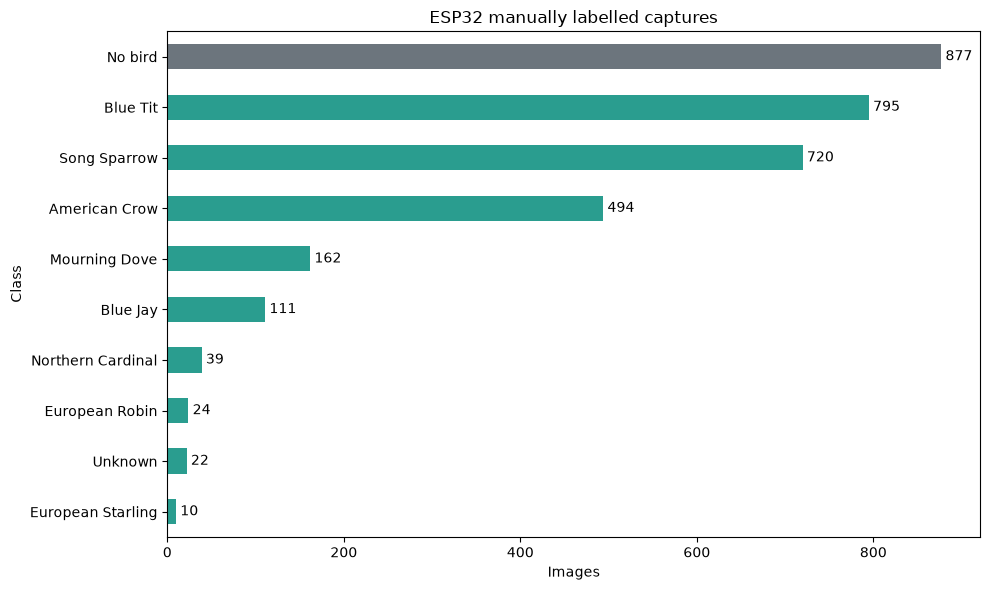

In [5]:
display(label_summary)

plot_data = label_summary.sort_values("image_count", ascending=True)
colors = ["#6c757d" if name == "No bird" else "#2a9d8f" for name in plot_data["class_name"]]
ax = plot_data.plot.barh(
    x="class_name",
    y="image_count",
    color=colors,
    legend=False,
    figsize=(10, 6),
)
ax.set(title="ESP32 manually labelled captures", xlabel="Images", ylabel="Class")
ax.bar_label(ax.containers[0], padding=3)
plt.tight_layout()
plt.show()


## 6. Representative capture preview

Display one deterministic example per class as a quick visual label check.


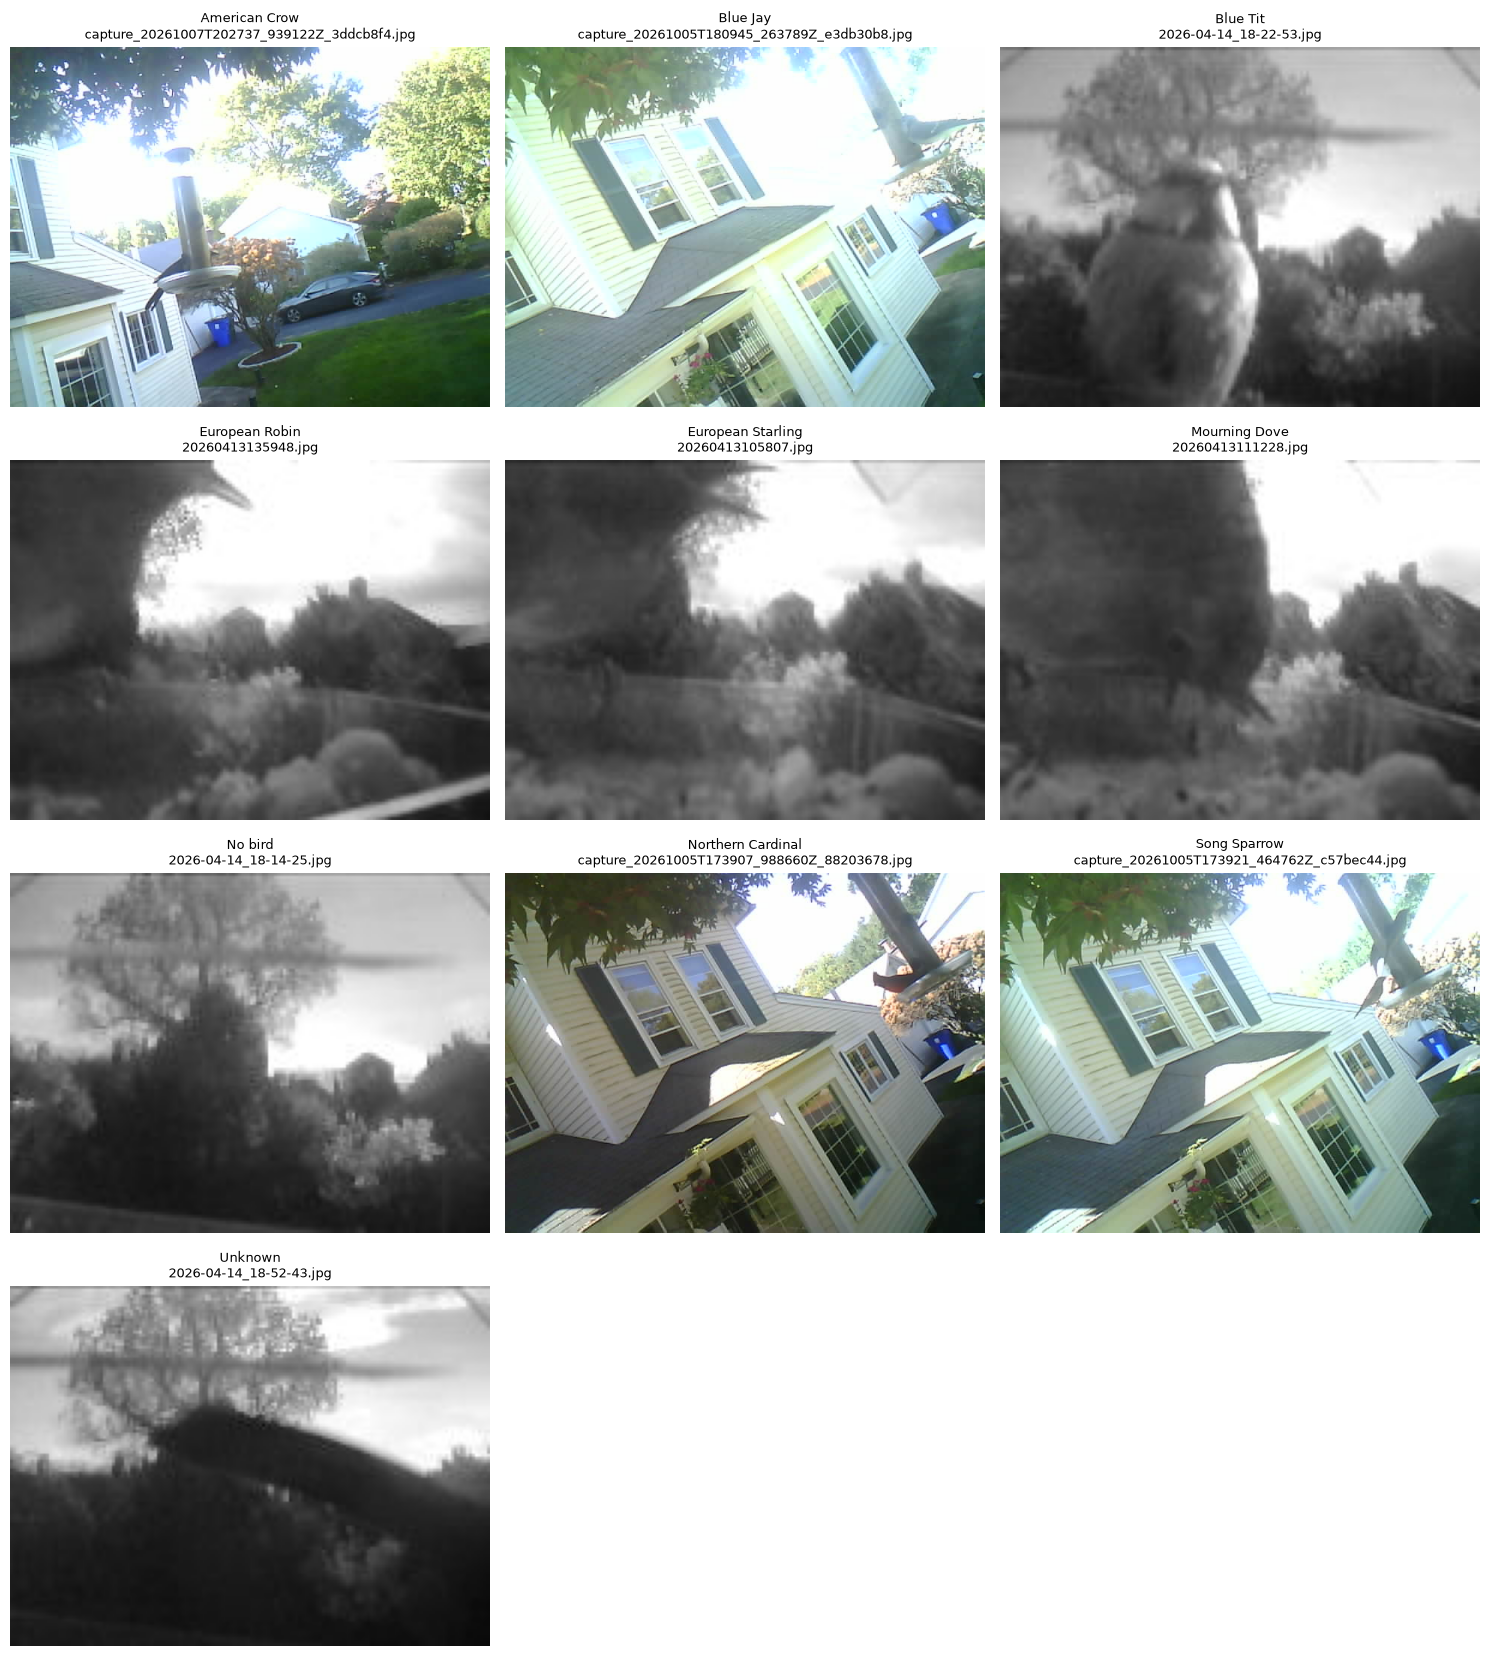

In [6]:
examples = (
    labeled_manifest.sort_values(["class_name", "image_relative_path"])
    .groupby("class_name", sort=True, as_index=False)
    .first()
)
columns = 3
rows = (len(examples) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(15, 4.2 * rows))
axes = axes.ravel()

for axis, (_, record) in zip(axes, examples.iterrows()):
    with Image.open(record["image_path"]) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(f"{record['class_name']}\n{record['filename']}", fontsize=9)
    axis.axis("off")

for axis in axes[len(examples):]:
    axis.axis("off")

plt.tight_layout()
plt.show()


## Downstream use

Use `esp32_labeled_manifest.csv` for training or evaluation. Useful columns include:

- `image_path`: absolute image path
- `bird_present` / `binary_label`: binary target (`false`/`0`, `true`/`1`)
- `species`: manual species label, blank for no-bird rows
- `class_name`: species for birds and `No bird` for negatives
- `image_sha256`: content identity for duplicate/leakage checks
- `width_px`, `height_px`: source dimensions

Before training, decide deliberately whether the positive-bird `Unknown` class should remain, be excluded, or be used only for binary bird detection.
